Health Study – Data Science Project

1. Introduction

The purpose of this project is to analyze a health-related dataset
using Python and statistical methods.

The analysis will investigate relationships between different
health variables and the occurrence of disease.

The project includes data exploration, descriptive statistics,
data visualization, simulations, confidence intervals
and hypothesis testing.

2. Objectives

- Explore and understand the dataset.
- Calculate descriptive statistics.
- Visualize relationships between health variables.
- Perform statistical simulations.
- Calculate confidence intervals.
- Conduct hypothesis testing.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

## 3. Data Loading and Initial Exploration

In this section, we load the health dataset using Pandas
and perform an initial examination of its structure.

In [2]:
df = pd.read_csv("../data/health_study_dataset.csv")

In [3]:
import sys
sys.path.append("..")

In [4]:
from src.health_analyzer import HealthAnalyzer

In [5]:
analyzer = HealthAnalyzer(df)

In [6]:
analyzer.mean_blood_pressure()

np.float64(149.178625)

In [7]:
analyzer.median_blood_pressure()

np.float64(149.4)

In [8]:
print("Minimum:", analyzer.min_blood_pressure())
print("Maximum:", analyzer.max_blood_pressure())

Minimum: 106.8
Maximum: 185.9


In [9]:
from src.health_functions import (
    calculate_disease_prevalence,
    calculate_confidence_interval,
    calculate_linear_regression,
    calculate_r_squared
)

In [10]:
prevalence = calculate_disease_prevalence(df)

print(f"Disease prevalence: {prevalence:.2%}")

Disease prevalence: 5.88%


In [11]:
lower, upper = calculate_confidence_interval(df)

print(f"95% Confidence Interval: {lower:.2f} - {upper:.2f}")

95% Confidence Interval: 148.29 - 150.07


In [12]:
slope, intercept = calculate_linear_regression(df)

print(f"Slope: {slope:.4f}")
print(f"Intercept: {intercept:.4f}")

Slope: 0.5360
Intercept: 122.6849


In [29]:
r_squared = calculate_r_squared(df, slope, intercept)

print(f"R-squared: {r_squared:.4f}")

R-squared: 0.3692


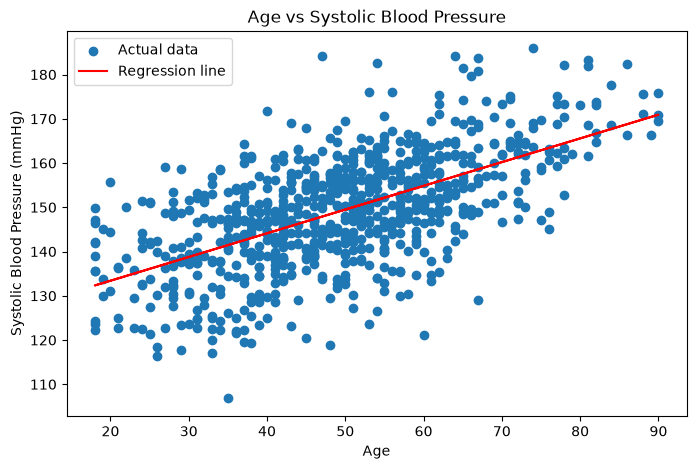

In [13]:
# Create scatter plot with regression line

plt.figure(figsize=(8, 5))

plt.scatter(df["age"], df["systolic_bp"], label="Actual data")

plt.plot(
    df["age"],
    intercept + slope * df["age"],
    color="red",
    label="Regression line"
)

plt.title("Age vs Systolic Blood Pressure")
plt.xlabel("Age")
plt.ylabel("Systolic Blood Pressure (mmHg)")
plt.legend()
plt.show()

### Interpretation of the regression analysis

The R-squared value is 0.3692, which means that approximately 36.92% of the variation in systolic blood pressure can be explained by age in our linear regression model.

This indicates a positive relationship between age and blood pressure, but age alone does not explain all the variation. Other factors also influence blood pressure.

In [14]:
df.head()

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


3.1 Dataset Overview

We begin by examining the dimensions and structure
of the dataset.

In [15]:
df.shape

(800, 9)

In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


In [17]:
df.isna().sum()

id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64

In [18]:
df.describe()

,id,age,height,weight,systolic_bp,cholesterol,disease
count,800.0000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000
mean,400.5000,49.426250,171.849250,73.413000,149.178625,4.929150,0.058750
std,231.0844,14.501118,9.804259,13.685059,12.793360,0.848413,0.235303
min,1.0000,18.000000,144.400000,33.700000,106.800000,2.500000,0.000000
25%,200.7500,39.000000,164.775000,64.800000,140.900000,4.327500,0.000000
50%,400.5000,50.000000,171.350000,73.200000,149.400000,4.970000,0.000000
75%,600.2500,59.000000,178.925000,82.600000,157.600000,5.482500,0.000000
max,800.0000,90.000000,200.400000,114.400000,185.900000,7.880000,1.000000


### 3.2 Descriptive Statistics

The dataset contains 800 observations and 9 variables.
No missing values were found in the dataset.

Descriptive statistics were calculated to examine the distribution
and central tendency of the numerical variables.

### 3.3 Data Visualization

#### 3.3.1 Age Distribution

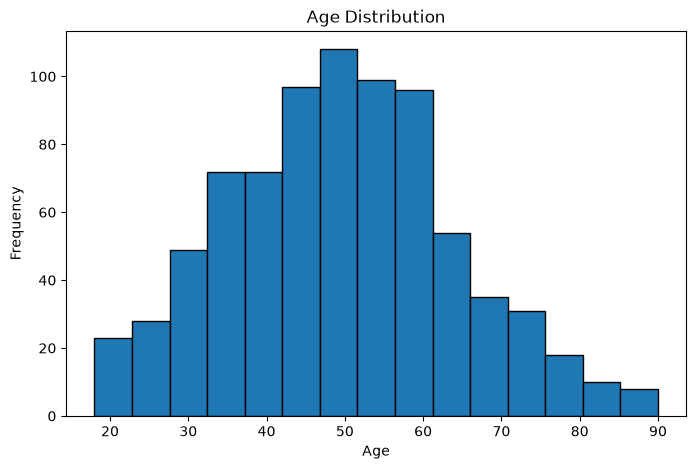

In [19]:
plt.figure(figsize=(8, 5))

plt.hist(df["age"], bins=15, edgecolor="black")

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

The histogram shows the age distribution of the 800 observations.
Most individuals are between 40 and 60 years old, with a peak
around 50 years. The distribution has fewer observations at
the higher age ranges.

#### 3.3.2 Systolic Blood Pressure Distribution

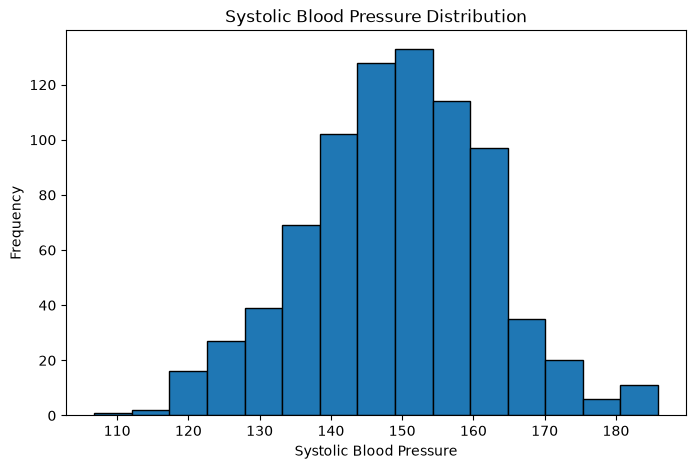

In [20]:
plt.figure(figsize=(8, 5))

plt.hist(df["systolic_bp"], bins=15, edgecolor="black")

plt.title("Systolic Blood Pressure Distribution")
plt.xlabel("Systolic Blood Pressure")
plt.ylabel("Frequency")

plt.show()

The histogram shows the distribution of systolic blood pressure
among the 800 observations. Most values are concentrated between
approximately 135 and 165, with a peak around 150. The distribution
appears approximately bell-shaped.

In [21]:
df["smoker"].value_counts()

smoker
No     587
Yes    213
Name: count, dtype: int64

#### 3.3.3 Systolic Blood Pressure by Smoking Status

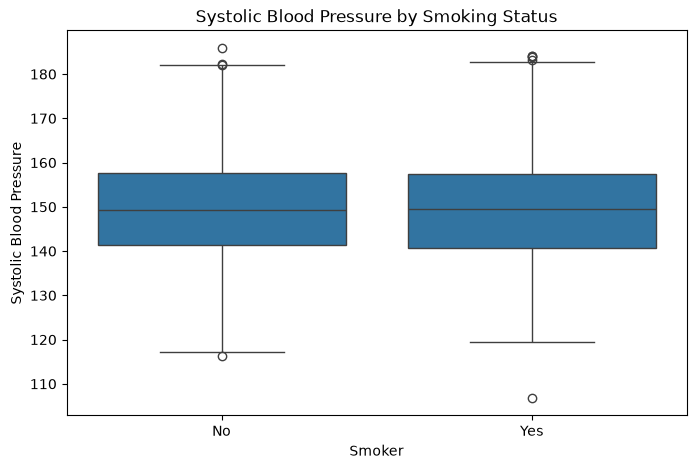

In [22]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="smoker", y="systolic_bp")

plt.title("Systolic Blood Pressure by Smoking Status")
plt.xlabel("Smoker")
plt.ylabel("Systolic Blood Pressure")

plt.show()

The boxplot compares systolic blood pressure between smokers and
non-smokers. Both groups have similar median values and comparable
distributions. Some outliers are present in both groups. No clear
difference between the groups can be observed from the visualization.

### 3.4 Disease Prevalence Simulation

In [23]:
df["disease"].value_counts()

disease
0    753
1     47
Name: count, dtype: int64

In [24]:
disease_cases = df["disease"].sum()
total_observations = len(df)

prevalence = disease_cases / total_observations

print(f"Disease cases: {disease_cases}")
print(f"Total observations: {total_observations}")
print(f"Disease prevalence: {prevalence:.2%}")

Disease cases: 47
Total observations: 800
Disease prevalence: 5.88%


In [25]:

# Simulate disease prevalence for 1000 people
np.random.seed(42)

simulation_size = 1000

simulated_data = np.random.binomial(
    n=1,
    p=prevalence,
    size=simulation_size
)

simulated_cases = simulated_data.sum()
simulated_prevalence = simulated_cases / simulation_size

print(f"Simulated population: {simulation_size}")
print(f"Simulated disease cases: {simulated_cases}")
print(f"Simulated prevalence: {simulated_prevalence:.2%}")


Simulated population: 1000
Simulated disease cases: 56
Simulated prevalence: 5.60%



The observed disease prevalence was 5.88%, based on
47 cases among 800 observations.

A binomial simulation using NumPy generated 56
disease cases among 1000 simulated individuals,
corresponding to a simulated prevalence of 5.60%.

The simulated prevalence was close to the observed
prevalence. Small differences are expected due to
random variation.


### 3.5 Confidence Interval for Mean Blood Pressure

In [26]:

# Calculate the sample statistics
mean_bp = df["systolic_bp"].mean()
std_bp = df["systolic_bp"].std()
n = len(df["systolic_bp"])

# Calculate the standard error
standard_error = std_bp / np.sqrt(n)

# Calculate the critical t-value
t_critical = stats.t.ppf(0.975, df=n - 1)

# Calculate the confidence interval
margin_of_error = t_critical * standard_error

lower_bound = mean_bp - margin_of_error
upper_bound = mean_bp + margin_of_error

print(f"Mean blood pressure: {mean_bp:.2f}")
print(f"Standard error: {standard_error:.4f}")
print(f"95% Confidence Interval: ({lower_bound:.2f}, {upper_bound:.2f})")


Mean blood pressure: 149.18
Standard error: 0.4523
95% Confidence Interval: (148.29, 150.07)



The mean systolic blood pressure was 149.18 mmHg.
The standard error was 0.4523.

The calculated 95% confidence interval was
148.29 to 150.07 mmHg.

This means that we are 95% confident that the
interval estimation method captures the true
population mean blood pressure.


### 3.6 Hypothesis Testing: Smokers vs Non-smokers

In [27]:

# Separate blood pressure values into two groups
smokers = df[df["smoker"] == "Yes"]["systolic_bp"]
non_smokers = df[df["smoker"] == "No"]["systolic_bp"]

# Calculate the mean blood pressure for each group
mean_smokers = smokers.mean()
mean_non_smokers = non_smokers.mean()

print(f"Mean blood pressure (smokers): {mean_smokers:.2f}")
print(f"Mean blood pressure (non-smokers): {mean_non_smokers:.2f}")


Mean blood pressure (smokers): 149.52
Mean blood pressure (non-smokers): 149.05


In [28]:

# Perform a one-sided Welch's t-test
t_statistic, p_value = stats.ttest_ind(
    smokers,
    non_smokers,
    equal_var=False,
    alternative="greater"
)

print(f"T-statistic: {t_statistic:.4f}")
print(f"P-value: {p_value:.4f}")



T-statistic: 0.4503
P-value: 0.3264



The one-sided Welch's t-test was used to compare
the mean systolic blood pressure between smokers
and non-smokers.

The p-value was 0.3264, which is higher than the
significance level of 0.05.

Therefore, we fail to reject the null hypothesis.
There is insufficient statistical evidence to
conclude that smokers have higher mean systolic
blood pressure than non-smokers.
